#Module 1 : Données

##Cellule 1 : installation et chargement

In [1]:
!pip install -q kagglehub pandas matplotlib seaborn

import kagglehub, os, pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

path = kagglehub.dataset_download("kartik2112/fraud-detection")
print(os.listdir(path))   # fraudTrain.csv, fraudTest.csv

tr = pd.read_csv(f"{path}/fraudTrain.csv", index_col=0)
te = pd.read_csv(f"{path}/fraudTest.csv", index_col=0)

# On fusionne : le découpage 60/20/20 sera fait nous-mêmes, chronologiquement
df = pd.concat([tr, te], ignore_index=True)
df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])
df = df.sort_values("trans_date_trans_time").reset_index(drop=True)

print(df.shape)
print(df["trans_date_trans_time"].min(), "→", df["trans_date_trans_time"].max())
df.head(3)

Using Colab cache for faster access to the 'fraud-detection' dataset.
['fraudTest.csv', 'fraudTrain.csv']
(1852394, 22)
2019-01-01 00:00:18 → 2020-12-31 23:59:34


,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0


##Cellule 2 : contrôles de base

In [2]:
print(df.dtypes, "\n")
print("Manquants :\n", df.isna().sum()[df.isna().sum() > 0])
print("Doublons de trans_num :", df["trans_num"].duplicated().sum())
print("Cartes distinctes :", df["cc_num"].nunique())

fraud_rate = df["is_fraud"].mean()
print(f"\nTaux de fraude : {fraud_rate:.4%}  "
      f"({df['is_fraud'].sum():,} fraudes / {len(df):,})")

trans_date_trans_time    datetime64[ns]
cc_num                            int64
merchant                         object
category                         object
amt                             float64
first                            object
last                             object
gender                           object
street                           object
city                             object
state                            object
zip                               int64
lat                             float64
long                            float64
city_pop                          int64
job                              object
dob                              object
trans_num                        object
unix_time                         int64
merch_lat                       float64
merch_long                      float64
is_fraud                          int64
dtype: object 

Manquants :
 Series([], dtype: int64)
Doublons de trans_num : 0
Cartes distinctes : 999

Taux de fraude 

un taux d’environ 0,5 %, donc un déséquilibre extrême. Note ce chiffre : il justifiera PR-AUC, précision@k et la stratégie du Module 2.

##Cellule 3 : montants par classe

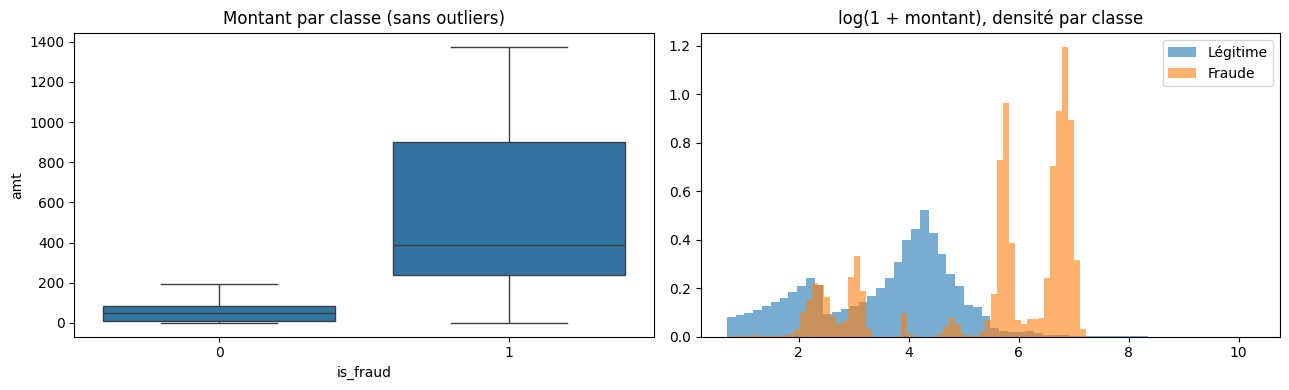

              count        mean         std   min      25%     50%      75%  \
is_fraud                                                                      
0         1842743.0   67.651278  153.548108  1.00    9.610   47.24   82.560   
1            9651.0  530.661412  391.028873  1.06  240.075  390.00  902.365   

               max  
is_fraud            
0         28948.90  
1          1376.04  


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

sns.boxplot(data=df, x="is_fraud", y="amt", ax=ax[0], showfliers=False)
ax[0].set_title("Montant par classe (sans outliers)")

for c, lab in [(0, "Légitime"), (1, "Fraude")]:
    ax[1].hist(np.log1p(df.loc[df.is_fraud == c, "amt"]), bins=60,
               alpha=.6, density=True, label=lab)
ax[1].set_title("log(1 + montant), densité par classe")
ax[1].legend()
plt.tight_layout(); plt.show()

print(df.groupby("is_fraud")["amt"].describe())

Les fraudes ont en général des montants nettement plus élevés. Note-le : ça justifiera la variable « montant ÷ moyenne du client » au Module 2 et le coût en montants au Module 4.

##Cellule 4 : évolution du taux de fraude dans le temps

/tmp/ipykernel_4905/2815868739.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  m = df.set_index("trans_date_trans_time")["is_fraud"].resample("M").agg(["mean", "sum", "count"])


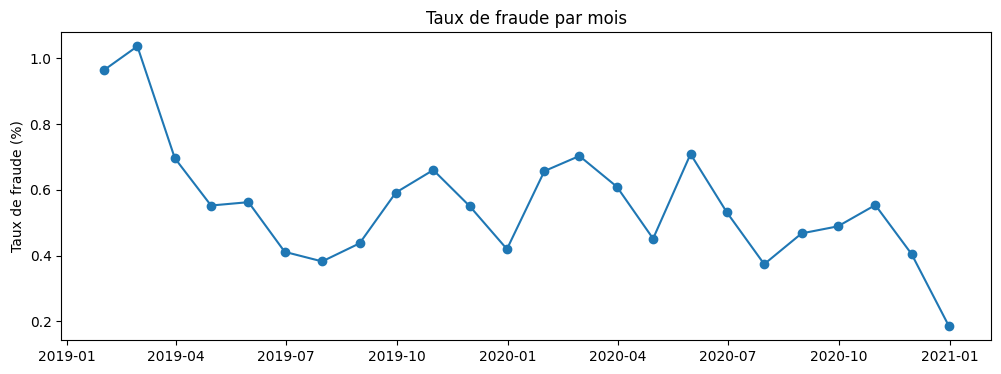

In [4]:
m = df.set_index("trans_date_trans_time")["is_fraud"].resample("M").agg(["mean", "sum", "count"])

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(m.index, m["mean"] * 100, marker="o")
ax.set_ylabel("Taux de fraude (%)"); ax.set_title("Taux de fraude par mois")
plt.show()

Cette courbe sert d’argument pour la séparation chronologique : si le taux dérive, un découpage aléatoire donnerait des résultats trop optimistes.

##Cellule 5 : taux de fraude par heure, catégorie, jour

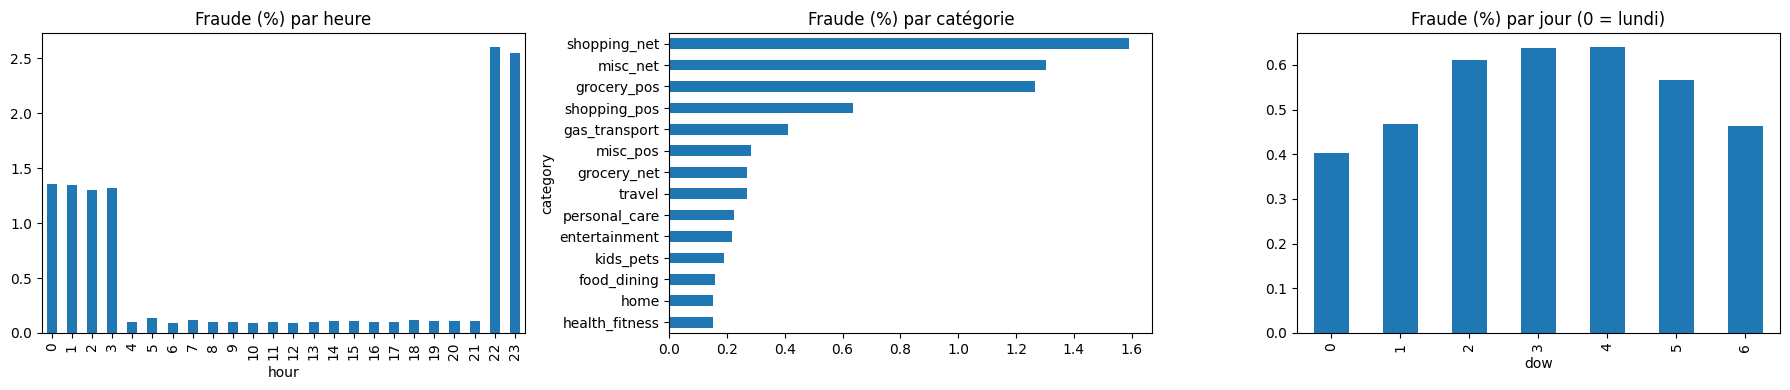

In [5]:
df["hour"] = df["trans_date_trans_time"].dt.hour
df["dow"]  = df["trans_date_trans_time"].dt.dayofweek

fig, ax = plt.subplots(1, 3, figsize=(18, 4))

df.groupby("hour")["is_fraud"].mean().mul(100).plot(kind="bar", ax=ax[0])
ax[0].set_title("Fraude (%) par heure")

df.groupby("category")["is_fraud"].mean().mul(100).sort_values().plot(kind="barh", ax=ax[1])
ax[1].set_title("Fraude (%) par catégorie")

df.groupby("dow")["is_fraud"].mean().mul(100).plot(kind="bar", ax=ax[2])
ax[2].set_title("Fraude (%) par jour (0 = lundi)")
plt.tight_layout(); plt.show()

Le pic nocturne (autour de 22 h–3 h) et certaines catégories (shopping_net, grocery_pos, misc_net) ressortent d’habitude. Ce sont les résultats à commenter dans ton rapport.

Un modèle doit apprendre ce qui rend une transaction suspecte (montant inhabituel, heure, rythme, lieu), pas qui est le client ni quelle ligne c’est.retiens que first, last, street, trans_num, dob sont des identifiants personnels ou inutiles : on les écartera des variables du modèle (sinon risque de fuite et d’explications absurdes en SHAP).

#Module 2 : Préparation et variables

##Cellule 1 : variables temporelles et distance

On construit tout sur le df du Module 1, déjà trié par date. Ce trie est indispensable pour les calculs qui suivent.

In [6]:
# Heure en codage cyclique : 23 h et 0 h doivent être "proches"
df["hour"] = df["trans_date_trans_time"].dt.hour
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["dow"] = df["trans_date_trans_time"].dt.dayofweek

df["log_amt"] = np.log1p(df["amt"])

# Distance client–marchand (haversine, en km)
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine(df["lat"], df["long"], df["merch_lat"], df["merch_long"])

##Cellule 2 : variables comportementales (sans fuite)

Pour chaque carte (cc_num), on calcule des statistiques uniquement sur son passé. La transaction courante n’est jamais comptée.

In [7]:
# Temps en secondes depuis 1970 (robuste selon la version de pandas)
ts = (df["trans_date_trans_time"] - pd.Timestamp("1970-01-01")).dt.total_seconds().values
amt = df["amt"].values

n = len(df)
tx_1h   = np.zeros(n)
tx_24h  = np.zeros(n)
ratio30 = np.full(n, np.nan)
secs_prev = np.full(n, np.nan)

H1, H24, D30 = 3600, 86400, 30 * 86400

for card, idx in df.groupby("cc_num").indices.items():
    # idx : positions des transactions de cette carte, déjà en ordre chronologique
    t = ts[idx]
    a = amt[idx]
    k = len(idx)
    pos = np.arange(k)

    # nombre de transactions passées dans la fenêtre (la courante est exclue)
    tx_1h[idx]  = pos - np.searchsorted(t, t - H1,  side="left")
    tx_24h[idx] = pos - np.searchsorted(t, t - H24, side="left")

    # montant moyen des transactions passées sur 30 jours
    left = np.searchsorted(t, t - D30, side="left")
    cs = np.concatenate([[0.0], np.cumsum(a)])
    somme = cs[pos] - cs[left]          # somme sur [left, i-1]
    cnt = pos - left
    with np.errstate(divide="ignore", invalid="ignore"):
        moy = np.where(cnt > 0, somme / cnt, np.nan)
    ratio30[idx] = a / moy

    # temps écoulé depuis la transaction précédente
    secs_prev[idx[1:]] = np.diff(t)

df["tx_1h"] = tx_1h
df["tx_24h"] = tx_24h
df["amt_ratio_30d"] = ratio30
df["secs_since_prev"] = secs_prev
df[["tx_1h", "tx_24h", "amt_ratio_30d", "secs_since_prev"]].describe()

,tx_1h,tx_24h,amt_ratio_30d,secs_since_prev
count,1.852394e+06,1.852394e+06,1.851395e+06,1.851395e+06
mean,2.000228e-01,4.110753e+00,1.055882e+00,3.093948e+04
std,4.756577e-01,3.255199e+00,2.741669e+00,4.532899e+04
min,0.000000e+00,0.000000e+00,1.166792e-03,0.000000e+00
25%,0.000000e+00,2.000000e+00,1.661134e-01,5.698000e+03
50%,0.000000e+00,3.000000e+00,6.718198e-01,1.569500e+04
75%,0.000000e+00,6.000000e+00,1.263832e+00,3.813500e+04
max,8.000000e+00,3.500000e+01,6.763881e+02,1.341471e+06


Fenêtre sur le passé seulement : pos - left compte les transactions avant la courante.

Aucune étiquette utilisée : on n’utilise que amt et les dates, jamais is_fraud. Utiliser le nombre de fraudes passées demanderait de tenir compte du délai de confirmation, donc on évite.

Valeurs manquantes normales : la première transaction d’une carte n’a ni précédente (secs_since_prev) ni historique (amt_ratio_30d). On laisse NaN (XGBoost le gère)

In [8]:
c = df["cc_num"].iloc[0]
df[df.cc_num == c][["trans_date_trans_time", "amt", "tx_1h", "tx_24h",
                    "amt_ratio_30d", "secs_since_prev"]].head(8)

,trans_date_trans_time,amt,tx_1h,tx_24h,amt_ratio_30d,secs_since_prev
0,2019-01-01 00:00:18,4.97,0.0,0.0,NaN,NaN
1565,2019-01-01 16:53:34,114.79,0.0,1.0,23.096579,60796.0
2299,2019-01-01 23:02:37,16.55,0.0,2.0,0.276386,22143.0
3606,2019-01-03 01:40:38,27.70,0.0,0.0,0.609640,95881.0
4227,2019-01-03 15:24:11,43.72,0.0,1.0,1.066276,49413.0
5044,2019-01-04 06:18:05,196.25,0.0,1.0,4.723680,53634.0
5175,2019-01-04 08:59:57,77.89,0.0,2.0,1.156839,9712.0
5493,2019-01-04 14:19:03,9.08,0.0,3.0,0.131903,19146.0


#Les 4 variables, en mots simples

##tx_1h:
	Combien de fois cette carte a-t-elle déjà servi dans l’heure avant cette transaction ?
##tx_24h:
	Même question sur les 24 h précédentes
##amt_ratio_30d:
	Ce montant vaut combien de fois la dépense moyenne de la carte sur les 30 derniers jours ?
##secs_since_prev:
	Combien de secondes depuis la transaction précédente de la carte ?

##Cellule 3 : choix des variables du modèle

In [9]:
a_ecarter = ["first", "last", "street", "trans_num", "dob",   # identité
             "cc_num",                                         # sert au regroupement seulement
             "merchant", "job", "city", "state", "zip",         # trop de modalités / quasi-identifiants
             "lat", "long", "merch_lat", "merch_long",          # remplacés par distance_km
             "unix_time", "trans_date_trans_time",
             "gender"]                                          # variable sensible, écartée par prudence

feat = df.drop(columns=a_ecarter + ["hour"])
feat = pd.get_dummies(feat, columns=["category"], drop_first=False)

y = feat.pop("is_fraud")
X = feat
print(X.shape); print(list(X.columns))


(1852394, 25)
['amt', 'city_pop', 'dow', 'hour_sin', 'hour_cos', 'log_amt', 'distance_km', 'tx_1h', 'tx_24h', 'amt_ratio_30d', 'secs_since_prev', 'category_entertainment', 'category_food_dining', 'category_gas_transport', 'category_grocery_net', 'category_grocery_pos', 'category_health_fitness', 'category_home', 'category_kids_pets', 'category_misc_net', 'category_misc_pos', 'category_personal_care', 'category_shopping_net', 'category_shopping_pos', 'category_travel']


j’ai écarté gender (variable sensible, un modèle de fraude n’a pas à l’utiliser) et dob

##Cellule 4 : découpage chronologique 60/20/20

In [10]:
n = len(X)
i1, i2 = int(0.6 * n), int(0.8 * n)

X_tr, y_tr = X.iloc[:i1],   y.iloc[:i1]
X_va, y_va = X.iloc[i1:i2], y.iloc[i1:i2]
X_te, y_te = X.iloc[i2:],   y.iloc[i2:]

dates = df["trans_date_trans_time"]
for nom, sl, yy in [("train", slice(0, i1), y_tr), ("val", slice(i1, i2), y_va), ("test", slice(i2, n), y_te)]:
    d = dates.iloc[sl]
    print(f"{nom:5s}  {d.min().date()} → {d.max().date()}  "
          f"n={len(yy):,}  fraudes={yy.sum():,}  taux={yy.mean():.3%}")

train  2019-01-01 → 2020-04-07  n=1,111,436  fraudes=6,401  taux=0.576%
val    2020-04-07 → 2020-08-25  n=370,479  fraudes=1,901  taux=0.513%
test   2020-08-25 → 2020-12-31  n=370,479  fraudes=1,349  taux=0.364%


##Pas de mélange aléatoire :
le modèle apprend sur le passé et est jugé sur un futur qu’il n’a jamais vu. Note les trois taux de fraude : s’ils diffèrent, c’est le décalage temporel qu’on veut précisément mesurer.

Les cartes présentes en test existent aussi en train, ce qui est réaliste en production (même clients, nouvelles transactions). Comme on n’utilise aucune colonne d’identité, ce n’est pas un problème.

##Cellule 5 : stratégie contre le déséquilibre, comparée en validation

Le sujet exige une comparaison en validation, et le déséquilibre est traité sur le train uniquement

In [12]:
import xgboost as xgb
from sklearn.metrics import average_precision_score

def fit_eval(Xtr, ytr, spw=1.0):
    m = xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                          subsample=0.8, colsample_bytree=0.8,
                          tree_method="hist", scale_pos_weight=spw,
                          eval_metric="aucpr", n_jobs=-1, random_state=42)
    m.fit(Xtr, ytr)
    return average_precision_score(y_va, m.predict_proba(X_va)[:, 1])

res = {}

# 1) Aucune stratégie
res["Aucune"] = fit_eval(X_tr, y_tr)

# 2) Pondération des classes
spw = (y_tr == 0).sum() / (y_tr == 1).sum()
res["Pondération (scale_pos_weight)"] = fit_eval(X_tr, y_tr, spw=spw)

# 3) Sous-échantillonnage : toutes les fraudes + 10 légitimes pour 1 fraude
rng = np.random.RandomState(42)
idx_f = np.where(y_tr.values == 1)[0]
idx_l = rng.choice(np.where(y_tr.values == 0)[0], size=10 * len(idx_f), replace=False)
idx = np.sort(np.concatenate([idx_f, idx_l]))
res["Sous-échantillonnage 1:10"] = fit_eval(X_tr.iloc[idx], y_tr.iloc[idx])

print(pd.Series(res, name="PR-AUC validation").round(4))
print("Référence aléatoire :", round(y_va.mean(), 4))

Aucune                            0.8994
Pondération (scale_pos_weight)    0.8970
Sous-échantillonnage 1:10         0.9083
Name: PR-AUC validation, dtype: float64
Référence aléatoire : 0.0051


les écarts sont faibles (moins de 0,013 entre le meilleur et le pire), et il s’agit d’un seul entraînement avec une seule graine. Je ne prétendrais pas que le sous-échantillonnage est « bien meilleur », seulement qu’il est le meilleur sur la validation et le plus rapide à entraîner.

#Module 3 : Modélisation

##Cellule 1 : corriger le suivi des résultats

In [13]:
def enregistrer(nom, type_, s_va, s_te, duree):
    """Convention : score élevé = transaction plus suspecte."""
    resultats[:] = [r for r in resultats if r["Modèle"] != nom]   # évite les doublons
    scores_va[nom], scores_te[nom] = s_va, s_te
    resultats.append({
        "Modèle": nom, "Type": type_,
        "PR-AUC (val)": average_precision_score(y_va, s_va),
        "ROC-AUC (val)": roc_auc_score(y_va, s_va),
        "Temps d'entraînement (s)": round(duree, 1),
    })
    print(f"{nom}: PR-AUC val = {resultats[-1]['PR-AUC (val)']:.4f}")

##Cellule 2 : repères simples (très utile pour interpréter)

Avant de juger un détecteur d’anomalies, compare-le à un score sans apprentissage : classer les transactions par une seule variable.

In [14]:
for col in ["log_amt", "amt_ratio_30d", "distance_km", "tx_1h"]:
    s = X_va[col].fillna(X_tr[col].median()).values
    print(f"{col:15s}  PR-AUC val = {average_precision_score(y_va, s):.4f}")
print("Référence aléatoire :", round(y_va.mean(), 4))

log_amt          PR-AUC val = 0.1641
amt_ratio_30d    PR-AUC val = 0.0850
distance_km      PR-AUC val = 0.0052
tx_1h            PR-AUC val = 0.0185
Référence aléatoire : 0.0051


##Cellule de préparation

In [16]:
import time
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import average_precision_score, roc_auc_score

# Au cas où la cellule 1 du Module 3 n'aurait pas été lancée
try:
    resultats
except NameError:
    resultats, scores_va, scores_te = [], {}, {}

# Variables numériques retenues pour les détecteurs d'anomalies
num  = ["log_amt", "city_pop", "distance_km", "hour_sin", "hour_cos",
        "tx_1h", "tx_24h", "amt_ratio_30d", "secs_since_prev"]
skew = ["city_pop", "tx_1h", "tx_24h", "amt_ratio_30d", "secs_since_prev"]

def prep(Xdf):
    Z = Xdf[num].astype("float32").copy()
    Z[skew] = np.log1p(Z[skew])        # variables très asymétriques
    return Z

# Imputation et standardisation : ajustées sur un échantillon du TRAIN uniquement
samp = np.random.RandomState(42).choice(len(X_tr), 50_000, replace=False)
imp2, sc2 = SimpleImputer(strategy="median"), StandardScaler()
Z_fit = sc2.fit_transform(imp2.fit_transform(prep(X_tr.iloc[samp])))

# Application aux trois ensembles
Z_tr = sc2.transform(imp2.transform(prep(X_tr)))
Z_va = sc2.transform(imp2.transform(prep(X_va)))
Z_te = sc2.transform(imp2.transform(prep(X_te)))

print(Z_tr.shape, Z_va.shape, Z_te.shape)

(1111436, 9) (370479, 9) (370479, 9)


##Cellule 3 : Isolation Forest

In [17]:
# Données numériques déjà préparées pour LOF (log + imputation + standardisation)
Z_tr = sc2.transform(imp2.transform(prep(X_tr)))   # imp2, sc2, Z_va, Z_te viennent de la cellule LOF

essais = []
for ms in [256, 1024, 4096]:
    for mf in [0.5, 1.0]:
        t0 = time.time()
        m = IsolationForest(n_estimators=200, max_samples=ms, max_features=mf,
                            n_jobs=-1, random_state=42).fit(Z_tr)
        s = -m.score_samples(Z_va)
        essais.append((ms, mf, average_precision_score(y_va, s), time.time() - t0))
        print(f"max_samples={ms:5d}  max_features={mf}  PR-AUC val={essais[-1][2]:.4f}")

max_samples=  256  max_features=0.5  PR-AUC val=0.1328
max_samples=  256  max_features=1.0  PR-AUC val=0.1000
max_samples= 1024  max_features=0.5  PR-AUC val=0.0953
max_samples= 1024  max_features=1.0  PR-AUC val=0.0986
max_samples= 4096  max_features=0.5  PR-AUC val=0.0771
max_samples= 4096  max_features=1.0  PR-AUC val=0.0754


##Garde la meilleure combinaison, puis enregistre-la :

In [18]:
ms, mf, _, _ = max(essais, key=lambda e: e[2])
t0 = time.time()
iso = IsolationForest(n_estimators=200, max_samples=ms, max_features=mf,
                      n_jobs=-1, random_state=42).fit(Z_tr)
enregistrer(f"Isolation Forest (ms={ms}, mf={mf})", "Non supervisé",
            -iso.score_samples(Z_va), -iso.score_samples(Z_te), time.time() - t0)

Isolation Forest (ms=256, mf=0.5): PR-AUC val = 0.1328


Le choix des paramètres utilise les étiquettes de la validation,  Les étiquettes ne servent jamais à entraîner le détecteur.

##Cellule 4 : variante(novelty detection)

In [19]:
t0 = time.time()
iso_n = IsolationForest(n_estimators=200, max_samples=ms, max_features=mf,
                        n_jobs=-1, random_state=42).fit(Z_tr[(y_tr == 0).values])
enregistrer("Isolation Forest (entraîné sur légitimes)", "Semi-supervisé",
            -iso_n.score_samples(Z_va), -iso_n.score_samples(Z_te), time.time() - t0)

Isolation Forest (entraîné sur légitimes): PR-AUC val = 0.1145


##Cellule 5 : LOF

In [23]:
essais_lof = {}   # k -> (PR-AUC val, modèle, durée)

for k in [10, 20, 50]:
    t0 = time.time()
    m = LocalOutlierFactor(n_neighbors=k, novelty=True, n_jobs=-1).fit(Z_fit)
    s = -m.score_samples(Z_va)                 # score élevé = plus suspect
    pr = average_precision_score(y_va, s)
    essais_lof[k] = (pr, m, time.time() - t0)
    print(f"n_neighbors={k:3d}  PR-AUC val={pr:.4f}  ({essais_lof[k][2]:.0f}s)")

# Meilleur k selon la PR-AUC en validation
k_best = max(essais_lof, key=lambda k: essais_lof[k][0])
pr_best, lof_best, duree = essais_lof[k_best]
print(f"\nMeilleur k = {k_best}  (PR-AUC val = {pr_best:.4f})")

# Enregistrement dans le tableau comparatif
enregistrer(f"LOF (k={k_best}, n=50 000)", "Non supervisé",
            -lof_best.score_samples(Z_va),
            -lof_best.score_samples(Z_te),
            duree)

n_neighbors= 10  PR-AUC val=0.0589  (41s)
n_neighbors= 20  PR-AUC val=0.0572  (51s)
n_neighbors= 50  PR-AUC val=0.0518  (73s)

Meilleur k = 10  (PR-AUC val = 0.0589)
LOF (k=10, n=50 000): PR-AUC val = 0.0589


##Cellule 6 : troisième méthode, One-Class SVM

In [24]:
from sklearn.svm import OneClassSVM

t0 = time.time()
ocsvm = OneClassSVM(kernel="rbf", gamma="scale", nu=0.01).fit(Z_fit[:20_000])
enregistrer("One-Class SVM (n=20 000)", "Non supervisé",
            -ocsvm.decision_function(Z_va), -ocsvm.decision_function(Z_te), time.time() - t0)

One-Class SVM (n=20 000): PR-AUC val = 0.0286


##Cellule 7 : tableau comparatif

In [25]:
tab = (pd.DataFrame(resultats).sort_values("PR-AUC (val)", ascending=False)
         .round(4).reset_index(drop=True))
print(f"Référence aléatoire (PR-AUC) : {y_va.mean():.4f}")
tab

Référence aléatoire (PR-AUC) : 0.0051


,Modèle,Type,PR-AUC (val),ROC-AUC (val),Temps d'entraînement (s)
0,"Isolation Forest (ms=256, mf=0.5)",Non supervisé,0.1328,0.8634,12.3
1,Isolation Forest (entraîné sur légitimes),Semi-supervisé,0.1145,0.8539,16.9
2,"LOF (k=10, n=50 000)",Non supervisé,0.0589,0.7215,41.0
3,One-Class SVM (n=20 000),Non supervisé,0.0286,0.7515,17.4


Isolation Forest est le meilleur non supervisé, nettement devant LOF (×2,3) et One-Class SVM (×4,6). C’est celui que tu garderas comme méthode non supervisée principale.

##Étape 1 : Isolation Forest, grille élargie python

In [27]:
# 1) Isolation Forest : grille élargie, meilleur choix sur la validation
essais_if = {}
for ms in [64, 128, 256]:
    for mf in [0.3, 0.5]:
        t0 = time.time()
        m = IsolationForest(n_estimators=200, max_samples=ms, max_features=mf,
                            n_jobs=-1, random_state=42).fit(Z_tr)
        pr = average_precision_score(y_va, -m.score_samples(Z_va))
        essais_if[(ms, mf)] = (pr, m, time.time() - t0)
        print(f"IF  ms={ms:4d}  mf={mf}  PR-AUC val={pr:.4f}")

(ms_b, mf_b) = max(essais_if, key=lambda c: essais_if[c][0])
pr_b, iso_b, d = essais_if[(ms_b, mf_b)]
print(f"\nMeilleur : ms={ms_b}, mf={mf_b}  (PR-AUC val = {pr_b:.4f})")

resultats[:] = [r for r in resultats if not r["Modèle"].startswith("Isolation Forest (ms=")]
enregistrer(f"Isolation Forest (ms={ms_b}, mf={mf_b})", "Non supervisé",
            -iso_b.score_samples(Z_va), -iso_b.score_samples(Z_te), d)

# 2) Tableau comparatif avec précision@k et rappel@k
def prec_rec_at_k(y_true, score, k):
    top = np.argsort(-score)[:k]
    tp = y_true.values[top].sum()
    return tp / k, tp / y_true.sum()

K = 1000
tab = pd.DataFrame(resultats)
tab[f"Précision@{K}"] = [prec_rec_at_k(y_va, scores_va[n], K)[0] for n in tab["Modèle"]]
tab[f"Rappel@{K}"]    = [prec_rec_at_k(y_va, scores_va[n], K)[1] for n in tab["Modèle"]]
tab = tab.sort_values("PR-AUC (val)", ascending=False).round(4).reset_index(drop=True)
print(f"Référence aléatoire (PR-AUC) : {y_va.mean():.4f}")
tab

IF  ms=  64  mf=0.3  PR-AUC val=0.0926
IF  ms=  64  mf=0.5  PR-AUC val=0.0815
IF  ms= 128  mf=0.3  PR-AUC val=0.1143
IF  ms= 128  mf=0.5  PR-AUC val=0.1266
IF  ms= 256  mf=0.3  PR-AUC val=0.1051
IF  ms= 256  mf=0.5  PR-AUC val=0.1328

Meilleur : ms=256, mf=0.5  (PR-AUC val = 0.1328)
Isolation Forest (ms=256, mf=0.5): PR-AUC val = 0.1328
Référence aléatoire (PR-AUC) : 0.0051


,Modèle,Type,PR-AUC (val),ROC-AUC (val),Temps d'entraînement (s),Précision@1000,Rappel@1000
0,"Isolation Forest (ms=256, mf=0.5)",Non supervisé,0.1328,0.8634,7.0,0.295,0.1552
1,Isolation Forest (entraîné sur légitimes),Semi-supervisé,0.1145,0.8539,16.9,0.273,0.1436
2,"LOF (k=10, n=50 000)",Non supervisé,0.0589,0.7215,41.0,0.146,0.0768
3,One-Class SVM (n=20 000),Non supervisé,0.0286,0.7515,17.4,0.107,0.0563


Trois détecteurs d’anomalies non supervisés ont été comparés en validation : Isolation Forest, Local Outlier Factor (LOF) et One-Class SVM. Le taux de fraude étant de 0,51 % en validation, la PR-AUC d’un classement aléatoire est d’environ 0,005. Isolation Forest obtient la meilleure PR-AUC (0,133, soit environ 26 fois le hasard) et la meilleure précision@1000 (0,295 : 295 fraudes parmi les 1 000 transactions les plus suspectes), devant LOF (0,059 ; 0,146) et One-Class SVM (0,029 ; 0,107). Ces scores restent modestes, ce qui est attendu : un détecteur non supervisé repère des transactions rares, pas nécessairement frauduleuses. L’hyperparamétrage (nombre d’échantillons par arbre, proportion de variables, nombre de voisins) a été réalisé sur la validation. Entraîner Isolation Forest uniquement sur des transactions légitimes ne l’améliore pas (PR-AUC de 0,115), ce qui indique que la contamination à 0,5 % n’altère pas l’apprentissage. Isolation Forest est retenu comme modèle de référence pour la suite

La précision@k demande un budget d’alertes k justifié. Mon k = 1000 était un choix de travail : sur les 140 jours de la validation, cela fait environ 7 alertes par jour, ce qui est très peu pour une banque. Au Module 4, on exprimera le budget en pourcentage des transactions (par exemple 0,5 %, soit environ 1 850 alertes) et on le reliera à la capacité d’un analyste et au coût d’analyse d’une alerte.


#Module 4 : Évaluation et seuil

##Cellule 1 : paramètres et données

In [28]:
from sklearn.metrics import (precision_recall_curve, fbeta_score,
                             matthews_corrcoef, average_precision_score, roc_auc_score)
import matplotlib.pyplot as plt

# --- Hypothèses métier  ---
C_ALERTE   = 10.0    # coût d'analyse d'une alerte, en $ (quelques minutes d'un analyste)
BUDGET_PCT = 0.01    # budget d'alertes : 1 % des transactions

yv, yt = y_va.values, y_te.values
amt_v, amt_t = X_va["amt"].values, X_te["amt"].values
modeles = [n for n in scores_va if "légitimes" not in n]   # non supervisé pur

# Budget k et capacité d'analyse correspondante
k_budget = int(BUDGET_PCT * len(yv))
jours_val = (dates.iloc[i1:i2].max() - dates.iloc[i1:i2].min()).days
print(f"Budget k = {k_budget:,} alertes sur {jours_val} jours "
      f"≈ {k_budget / jours_val:.0f} alertes/jour")
print(f"Montant moyen d'une fraude (val) : {amt_v[yv == 1].mean():.0f} $")
print(f"Seuil de rentabilité d'une alerte : précision ≥ {C_ALERTE / amt_v[yv == 1].mean():.1%}")

Budget k = 3,704 alertes sur 139 jours ≈ 27 alertes/jour
Montant moyen d'une fraude (val) : 520 $
Seuil de rentabilité d'une alerte : précision ≥ 1.9%


##Justification du budget :
 avec environ 2 600 transactions par jour, un budget de 1 % représente environ 26 alertes par jour, ce qui est réaliste pour un analyste (30 à 40 alertes par jour). Le dernier calcul est une règle utile : une alerte supplémentaire est rentable tant que sa probabilité d’être une fraude, multipliée par le montant moyen d’une fraude, dépasse son coût d’analyse. Le seuil optimal se trouvera donc là où la précision marginale descend à ce « seuil de rentabilité ».

##Cellule 2 : métriques de classement et à budget fixé

In [29]:
def metriques_topk(y, s, amt, k):
    top = np.argsort(-s)[:k]
    tp = y[top].sum()
    return tp / k, tp / y.sum(), amt[top][y[top] == 1].sum() / amt[y == 1].sum()

lignes = []
for n in modeles:
    p, r, ra = metriques_topk(yv, scores_va[n], amt_v, k_budget)
    lignes.append({"Modèle": n,
                   "PR-AUC": average_precision_score(yv, scores_va[n]),
                   "ROC-AUC": roc_auc_score(yv, scores_va[n]),
                   f"Précision@{k_budget}": p,
                   f"Rappel@{k_budget}": r,
                   f"% du montant fraudé couvert@{k_budget}": ra})
print(f"Référence aléatoire : PR-AUC = {yv.mean():.4f}, précision = {yv.mean():.4f}")
pd.DataFrame(lignes).round(4)

Référence aléatoire : PR-AUC = 0.0051, précision = 0.0051


,Modèle,PR-AUC,ROC-AUC,Précision@3704,Rappel@3704,% du montant fraudé couvert@3704
0,"Isolation Forest (ms=256, mf=0.5)",0.1328,0.8634,0.1509,0.2941,0.4680
1,"LOF (k=10, n=50 000)",0.0589,0.7215,0.0661,0.1289,0.1437
2,One-Class SVM (n=20 000),0.0286,0.7515,0.0624,0.1215,0.1860


##Cellule 3 : courbes précision-rappel superposées

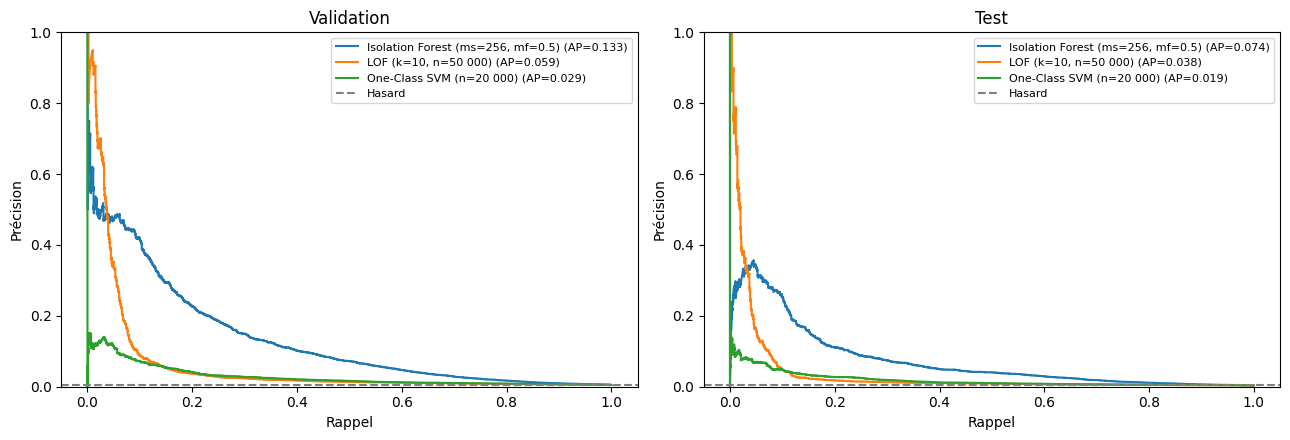

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (y, S, titre) in zip(axes, [(yv, scores_va, "Validation"), (yt, scores_te, "Test")]):
    for n in modeles:
        p, r, _ = precision_recall_curve(y, S[n])
        ax.plot(r, p, label=f"{n} (AP={average_precision_score(y, S[n]):.3f})")
    ax.axhline(y.mean(), color="gray", ls="--", label="Hasard")
    ax.set_xlabel("Rappel"); ax.set_ylabel("Précision"); ax.set_title(titre)
    ax.set_ylim(0, 1); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

##Cellule 4 : seuil choisi par coût sur la validation, confirmé sur le test

Coût = montants des fraudes manquées + C_ALERTE × nombre d’alertes.

In [31]:
def courbe_cout(y, s, amt, c):
    ordre = np.argsort(-s)
    caught = np.concatenate([[0], np.cumsum((amt * y)[ordre])])
    k = np.arange(len(y) + 1)
    cout = (amt * y).sum() - caught + c * k      # coût si on analyse les k plus suspects
    return ordre, cout

def eval_seuil(y, s, amt, thr, c):
    al = s >= thr
    tp, fn = (al & (y == 1)).sum(), ((~al) & (y == 1)).sum()
    cout = amt[(~al) & (y == 1)].sum() + c * al.sum()
    return {"alertes": int(al.sum()),
            "précision": tp / max(al.sum(), 1), "rappel": tp / (tp + fn),
            "F2": fbeta_score(y, al, beta=2), "MCC": matthews_corrcoef(y, al),
            "coût ($)": cout, "économie vs sans détecteur": 1 - cout / amt[y == 1].sum()}

res_val, res_te, seuils = [], [], {}
for n in modeles:
    ordre, cout = courbe_cout(yv, scores_va[n], amt_v, C_ALERTE)
    k_star = int(np.argmin(cout))
    thr = scores_va[n][ordre[k_star - 1]] if k_star > 0 else np.inf
    seuils[n] = (k_star, thr)
    res_val.append({"Modèle": n, "k*": k_star, "seuil": round(thr, 4),
                    **eval_seuil(yv, scores_va[n], amt_v, thr, C_ALERTE)})
    res_te.append({"Modèle": n, "seuil (de la val.)": round(thr, 4),
                   **eval_seuil(yt, scores_te[n], amt_t, thr, C_ALERTE)})

print("=== VALIDATION : seuil optimal ===")
display(pd.DataFrame(res_val).round(4))
print("=== TEST : même seuil, appliqué tel quel ===")
display(pd.DataFrame(res_te).round(4))

=== VALIDATION : seuil optimal ===


,Modèle,k*,seuil,alertes,précision,rappel,F2,MCC,coût ($),économie vs sans détecteur
0,"Isolation Forest (ms=256, mf=0.5)",18188,0.5556,18188,0.0581,0.5555,0.2047,0.1683,373834.89,0.6221
1,"LOF (k=10, n=50 000)",6315,1.2389,6315,0.0486,0.1615,0.1103,0.0801,876584.19,0.1139
2,One-Class SVM (n=20 000),23447,-1.1141,23447,0.0265,0.3267,0.1000,0.0777,762331.26,0.2294


=== TEST : même seuil, appliqué tel quel ===


,Modèle,seuil (de la val.),alertes,précision,rappel,F2,MCC,coût ($),économie vs sans détecteur
0,"Isolation Forest (ms=256, mf=0.5)",0.5556,23154,0.0331,0.5686,0.1343,0.1264,371089.78,0.4944
1,"LOF (k=10, n=50 000)",1.2389,9682,0.0221,0.1586,0.0710,0.0502,694679.51,0.0535
2,One-Class SVM (n=20 000),-1.1141,28982,0.0157,0.3380,0.0663,0.0585,677927.81,0.0763


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


##Cellule 5 : courbe de coût (Isolation Forest

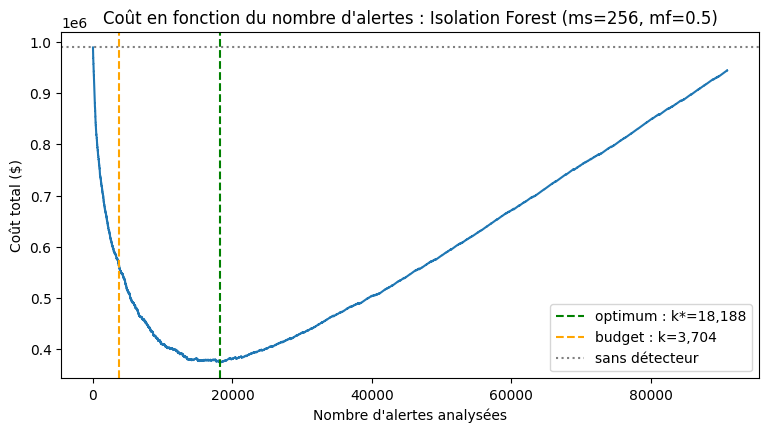

In [32]:
n_if = modeles[0] if "Isolation" not in "".join(modeles) else [m for m in modeles if "Isolation" in m][0]
ordre, cout = courbe_cout(yv, scores_va[n_if], amt_v, C_ALERTE)
k_star = seuils[n_if][0]

kmax = min(len(yv), max(5 * k_star, 3 * k_budget))
plt.figure(figsize=(9, 4.5))
plt.plot(np.arange(kmax), cout[:kmax])
plt.axvline(k_star, color="green", ls="--", label=f"optimum : k*={k_star:,}")
plt.axvline(k_budget, color="orange", ls="--", label=f"budget : k={k_budget:,}")
plt.axhline(cout[0], color="gray", ls=":", label="sans détecteur")
plt.xlabel("Nombre d'alertes analysées"); plt.ylabel("Coût total ($)")
plt.title(f"Coût en fonction du nombre d'alertes : {n_if}"); plt.legend(); plt.show()

##Cellule 6 : sensibilité au coût d’analyse (facultative, mais très valorisée)

In [33]:
lignes = []
for c in [2, 5, 10, 25, 50]:
    ordre, cout = courbe_cout(yv, scores_va[n_if], amt_v, c)
    ks = int(np.argmin(cout))
    lignes.append({"coût/alerte ($)": c, "k*": ks, "économie": 1 - cout[ks] / cout[0]})
pd.DataFrame(lignes).round(3)

,coût/alerte ($),k*,économie
0,2,40989,0.818
1,5,25749,0.721
2,10,18188,0.622
3,25,9372,0.438
4,50,3858,0.284


**Pourquoi le budget k = 1 %** : capacité d’un analyste, environ 26 alertes par jour.
**Le coût** : définition, hypothèse à 10 $ par alerte, tableau de sensibilité.

**Seuil vs budget** : le seuil optimal en coût peut dépasser le budget d’un analyste. C’est une vraie

**décision de gestion** : on peut soit couvrir plus d’alertes (plus de personnel), soit se limiter au budget en acceptant un coût plus élevé. Ton appli (curseurs seuil et budget) montrera précisément cet arbitrage.

**Confirmation sur le test** : compare le coût du test avec ce que donnerait son propre optimum, puis commente l’écart (dérive temporelle, moins de fraudes).

# ***Trois choses à retenir*** :

1)Isolation Forest est le seul détecteur qui vaut la peine d’être déployé : il réduit le coût de 49 % par rapport à l’absence de détecteur. LOF et One-Class SVM gagnent quelques pourcents seulement. C’est un argument fort pour ton choix.

2)Le seuil généralise correctement. L’économie passe de 62 % (validation, d’après ta table de sensibilité à 10 $) à 49 % (test). Elle baisse, mais elle reste largement positive, ce qui est la confirmation demandée.

3)Le même seuil déclenche plus d’alertes en test : 23 154 (6,2 % des transactions) contre environ 18 188 en validation (4,9 %). Les scores dérivent légèrement vers le haut avec le temps. En production, c’est une raison de surveiller et de recalibrer le seuil régulièrement.

In [34]:
n_if = [m for m in modeles if "Isolation" in m][0]

def cout_au_budget(y, s, amt, k, c):
    top = np.argsort(-s)[:k]
    manque = amt[y == 1].sum() - amt[top][y[top] == 1].sum()
    cout = manque + c * k
    return cout, 1 - cout / amt[y == 1].sum()

for nom, y, s, a in [("Validation", yv, scores_va[n_if], amt_v), ("Test", yt, scores_te[n_if], amt_t)]:
    k_b = int(BUDGET_PCT * len(y))
    c_b, e_b = cout_au_budget(y, s, a, k_b, C_ALERTE)
    print(f"{nom:10s} au budget (k={k_b:,}) : coût = {c_b:,.0f} $, économie = {e_b:.1%}")

pd.DataFrame(res_val).round(4)        # table de validation, en dernière ligne de la cellule

Validation au budget (k=3,704) : coût = 563,339 $, économie = 43.1%
Test       au budget (k=3,704) : coût = 478,584 $, économie = 34.8%


,Modèle,k*,seuil,alertes,précision,rappel,F2,MCC,coût ($),économie vs sans détecteur
0,"Isolation Forest (ms=256, mf=0.5)",18188,0.5556,18188,0.0581,0.5555,0.2047,0.1683,373834.89,0.6221
1,"LOF (k=10, n=50 000)",6315,1.2389,6315,0.0486,0.1615,0.1103,0.0801,876584.19,0.1139
2,One-Class SVM (n=20 000),23447,-1.1141,23447,0.0265,0.3267,0.1000,0.0777,762331.26,0.2294


Le seuil d’alerte a été choisi sur la validation en minimisant un coût égal aux montants des fraudes non détectées, plus 10 $ par alerte analysée. Pour Isolation Forest, l’optimum correspond à 18 188 alertes (4,9 % des transactions), avec un rappel de 55,6 % et une économie de 62,2 % par rapport à l’absence de détecteur. Appliqué sans réajustement au jeu de test, ce seuil conserve un rappel de 56,9 % et une économie de 49,4 %. La baisse de l’économie s’explique par un taux de fraude plus faible en test (0,36 % contre 0,51 %) et par une légère dérive des scores, qui déclenche 27 % d’alertes supplémentaires au même seuil. Ces valeurs, notamment le coût d’analyse de 10 $, reposent sur des hypothèses dont l’effet a été mesuré par une analyse de sensibilité (économie de 82 % à 2 $ jusqu’à 28 % à 50 $ par alerte). LOF et One-Class SVM n’apportent qu’un gain marginal en test (5,4 % et 7,6 %).

# Module 5 : Explainable AI

**Ce que l'on explique.** Le modèle retenu est Isolation Forest, non supervisé. Son score mesure à quel point une transaction est *inhabituelle*, pas à quel point elle est *frauduleuse*. Les explications répondent donc à : « qu'est-ce qui rend cette transaction atypique ? ». À préciser dans le rapport.

**Convention de signe.** On explique directement le score d'anomalie (élevé = suspect). Une contribution SHAP **positive** pousse vers l'alerte, une contribution **négative** rassure.

**Choix technique.** `shap.Explainer(..., algorithm="permutation")` est indépendant du modèle. On lui donne une fonction qui part des variables brutes (montant, distance, ...) et renvoie le score. Les explications portent ainsi sur des valeurs lisibles, et il n'y a pas de piège de signe propre à `TreeExplainer` sur Isolation Forest.

In [35]:
!pip install -q shap fastapi uvicorn httpx joblib
import os, sys, time
os.makedirs("api", exist_ok=True)

### Cellule 1 : module d'explication partagé

Ce fichier regroupe les 9 variables du modèle en 8 notions lisibles (`hour_sin` et `hour_cos` forment une seule information : l'heure) et fabrique les **codes motifs**. Le Module 6 réutilise exactement le même fichier : le notebook et l'API donnent donc les mêmes explications.

In [36]:
%%writefile api/explication.py
"""Outils d'explication partagés par le notebook (Module 5) et l'API (Module 6).

Aucune dépendance à SHAP ici : on reçoit des contributions déjà calculées
(contribution positive = la variable augmente le score d'anomalie = rend la
transaction plus suspecte) et on les regroupe / traduit en « codes motifs ».
"""
import numpy as np
import pandas as pd

# Les 9 variables du modèle sont regroupées en 8 notions lisibles par un analyste.
# (hour_sin et hour_cos forment ensemble UNE information : l'heure.
#  Les valeurs SHAP étant additives, on peut les additionner sans perte.)
GROUPES = {
    "Montant": ["log_amt"],
    "Population de la ville": ["city_pop"],
    "Distance client-marchand": ["distance_km"],
    "Heure": ["hour_sin", "hour_cos"],
    "Transactions sur 1 h": ["tx_1h"],
    "Transactions sur 24 h": ["tx_24h"],
    "Montant / moyenne 30 j": ["amt_ratio_30d"],
    "Délai depuis la précédente": ["secs_since_prev"],
}

CODES = {
    "Montant": "R01_MONTANT",
    "Population de la ville": "R02_VILLE",
    "Distance client-marchand": "R03_DISTANCE",
    "Heure": "R04_HEURE",
    "Transactions sur 1 h": "R05_VELOCITE_1H",
    "Transactions sur 24 h": "R06_VELOCITE_24H",
    "Montant / moyenne 30 j": "R07_ECART_PROFIL",
    "Délai depuis la précédente": "R08_DELAI",
}


def regrouper(values, X_num, num):
    """Regroupe les contributions par notion lisible.

    values : (n, 9) contributions dans l'ordre de `num`
    X_num  : DataFrame (n, 9) des variables du modèle (avant standardisation)
    Retourne (V, D, noms) :
      V = contributions regroupées (n, 8)
      D = valeurs lisibles associées (DataFrame n x 8 : montant en $, heure en h, ...)
      noms = liste des 8 notions
    """
    idx = {c: i for i, c in enumerate(num)}
    V = np.column_stack([values[:, [idx[c] for c in cols]].sum(axis=1)
                         for cols in GROUPES.values()])
    # heure d'origine à partir de (sin, cos) : angle = 2*pi*h/24 -> h = degrés / 15
    h = (np.degrees(np.arctan2(X_num["hour_sin"].values, X_num["hour_cos"].values)) / 15) % 24
    D = pd.DataFrame({
        "Montant": np.expm1(X_num["log_amt"].values),
        "Population de la ville": X_num["city_pop"].values,
        "Distance client-marchand": X_num["distance_km"].values,
        "Heure": np.round(h) % 24,
        "Transactions sur 1 h": X_num["tx_1h"].values,
        "Transactions sur 24 h": X_num["tx_24h"].values,
        "Montant / moyenne 30 j": X_num["amt_ratio_30d"].values,
        "Délai depuis la précédente": X_num["secs_since_prev"].values,
    })
    return V, D, list(GROUPES)


def _libelle(nom, v):
    """Phrase lisible pour un analyste."""
    manquant = v is None or (isinstance(v, float) and np.isnan(v))
    if nom == "Montant":
        return f"Montant inhabituel : {v:,.0f} $"
    if nom == "Population de la ville":
        return f"Ville de taille atypique : {v:,.0f} habitants"
    if nom == "Distance client-marchand":
        return f"Marchand à {v:,.0f} km du domicile du client"
    if nom == "Heure":
        return f"Transaction à {int(v)} h, heure peu habituelle"
    if nom == "Transactions sur 1 h":
        return f"{int(v)} transaction(s) déjà faite(s) avec cette carte dans l'heure précédente"
    if nom == "Transactions sur 24 h":
        return f"{int(v)} transaction(s) déjà faite(s) avec cette carte sur 24 h"
    if nom == "Montant / moyenne 30 j":
        if manquant:
            return "Aucun historique sur 30 j pour situer ce montant"
        return f"Montant = {v:.1f} × la dépense moyenne de la carte sur 30 j"
    if nom == "Délai depuis la précédente":
        if manquant:
            return "Première transaction connue de la carte"
        if v < 120:
            return f"Seulement {v:.0f} s après la transaction précédente"
        if v < 3600:
            return f"{v / 60:.0f} min après la transaction précédente"
        return f"{v / 3600:.1f} h après la transaction précédente"
    return nom


def motifs(contribs, valeurs, noms, k_max=5):
    """Codes motifs : les (au plus) k_max notions qui AUGMENTENT le plus le score.

    On ne garde que les contributions positives : un motif doit expliquer
    pourquoi la transaction est suspecte, pas pourquoi elle serait normale.
    """
    contribs = np.asarray(contribs, dtype=float)
    ordre = [i for i in np.argsort(-contribs) if contribs[i] > 0][:k_max]
    return [{"code": CODES[noms[i]],
             "variable": noms[i],
             "libelle": _libelle(noms[i], valeurs[i]),
             "contribution": round(float(contribs[i]), 4)} for i in ordre]

Writing api/explication.py


**Note sur `n_if`.** Dans le Module 4, `n_if` était pris par `[m for m in modeles if "Isolation" in m][0]`. Or `scores_va` garde l'ancienne entrée d'Isolation Forest après la grille élargie (l'« Étape 1 »). Si la meilleure combinaison a changé, ce `[0]` désigne l'ancien modèle et non `iso_b`. Ici le nom est reconstruit à partir de `ms_b` et `mf_b`, et l'`assert` ci-dessus vérifie la correspondance. Si l'`assert` échoue, relance les cellules de l'« Étape 1 » avant de continuer.

In [40]:
import shap, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, "api")
from explication import GROUPES, regrouper, motifs

# Le modèle explicable : celui dont les scores sont dans le tableau comparatif.
n_if = f"Isolation Forest (ms={ms_b}, mf={mf_b})"
thr_cout = seuils[n_if][1]                       # seuil optimal en coût (Module 4)
thr_budget = np.sort(scores_va[n_if])[-k_budget]   # score du k-ième plus suspect (budget 1 %)

# Fonction de score : variables brutes -> score d'anomalie (élevé = suspect)
def score_fn(A):
    D = pd.DataFrame(A, columns=num)
    return -iso_b.score_samples(sc2.transform(imp2.transform(prep(D))))

# Contrôle indispensable : cette fonction reproduit EXACTEMENT les scores du Module 4
ref = scores_va[n_if][:2000]
assert np.allclose(score_fn(X_va[num].values[:2000]), ref, atol=1e-4), "score_fn différent de scores_va"
print("Contrôle OK. Modèle expliqué :", n_if)

rng = np.random.RandomState(42)
bg = X_tr[num].values[rng.choice(len(X_tr), 50, replace=False)]   # fond de référence : 50 transactions du train
explainer = shap.Explainer(score_fn, shap.maskers.Independent(bg, max_samples=50),
                           algorithm="permutation", feature_names=num)

def expliquer(Xnum, max_evals):
    sv = explainer(Xnum[num].values, max_evals=max_evals)
    V, D, noms = regrouper(sv.values, Xnum, num)
    # contrôle d'additivité : base + somme des contributions = score du modèle
    ecart = np.abs(sv.base_values + sv.values.sum(axis=1) - score_fn(Xnum[num].values)).max()
    assert ecart < 1e-3, f"additivité SHAP non respectée ({ecart:.4f})"
    return shap.Explanation(values=V, base_values=sv.base_values, data=D.values,
                            feature_names=noms), V, D, noms

Contrôle OK. Modèle expliqué : Isolation Forest (ms=256, mf=0.5)


### Cellule 2 : explication globale (SHAP beeswarm)

Échantillon aléatoire de 1 000 transactions de la validation. Chaque point est une transaction : à droite, la variable la rend plus suspecte ; à gauche, moins suspecte. La couleur indique la valeur de la variable (gris : valeur manquante, par exemple première transaction d'une carte).

PermutationExplainer explainer: 1001it [02:39,  5.90it/s]


SHAP sur 1 000 transactions : 160 s


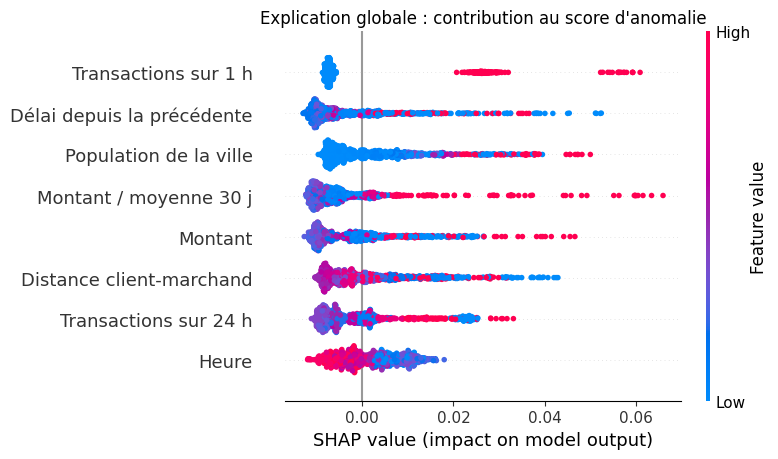

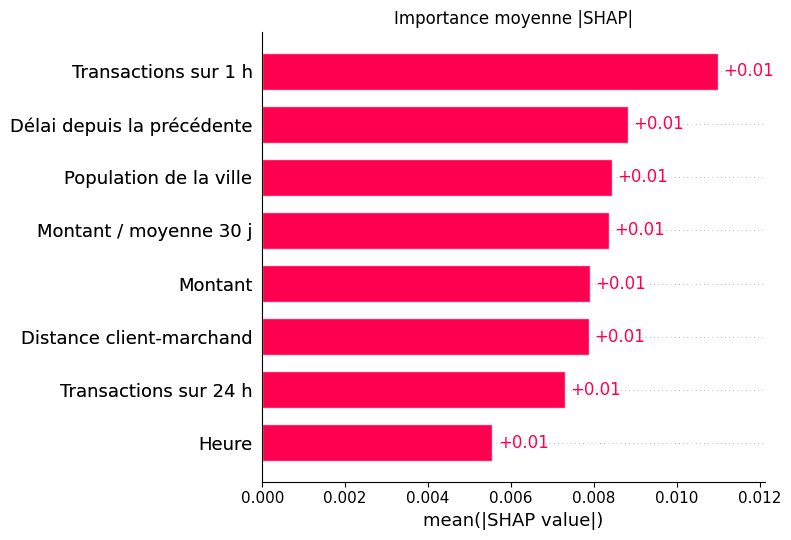

In [41]:
idx_s = rng.choice(len(X_va), 1000, replace=False)
t0 = time.time()
expl_g, V_g, D_g, noms = expliquer(X_va[num].iloc[idx_s], max_evals=6 * len(num) + 1)
print(f"SHAP sur 1 000 transactions : {time.time() - t0:.0f} s")

plt.figure()
shap.plots.beeswarm(expl_g, max_display=8, show=False)
plt.title("Explication globale : contribution au score d'anomalie")
plt.tight_layout(); plt.show()

plt.figure()
shap.plots.bar(expl_g, max_display=8, show=False)
plt.title("Importance moyenne |SHAP|"); plt.tight_layout(); plt.show()

### Cellule 3 : contre-vérification par importance par permutation

On mélange une variable (ou une notion entière, ce qui garde `hour_sin` et `hour_cos` cohérents) et on mesure la **perte de PR-AUC** en validation. Cette méthode utilise les vraies étiquettes. Elle dit donc quelles variables servent à *retrouver les fraudes*, alors que SHAP dit lesquelles *font bouger le score*. Les deux classements ne coïncident pas forcément, et c'est intéressant à commenter.

PR-AUC de référence (sous-échantillon de 100 000) : 0.1268  (36 s)


,Perte de PR-AUC
Montant / moyenne 30 j,0.0959
Montant,0.0879
Transactions sur 1 h,0.0515
Heure,0.0171
Distance client-marchand,0.0010
Délai depuis la précédente,-0.0002
Population de la ville,-0.0107
Transactions sur 24 h,-0.0229


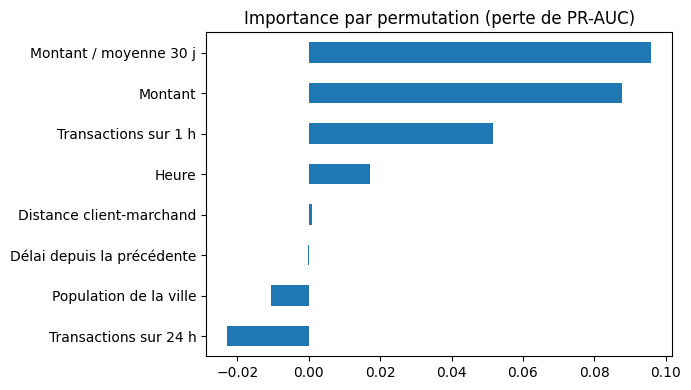

In [42]:
def importance_permutation(n=100_000, n_rep=3):
    idx = rng.choice(len(X_va), n, replace=False)
    A, y = X_va[num].values[idx], y_va.values[idx]
    base = average_precision_score(y, score_fn(A))
    pos = {c: i for i, c in enumerate(num)}
    out = {}
    for nom, cols in GROUPES.items():
        j = [pos[c] for c in cols]
        pertes = []
        for _ in range(n_rep):
            B = A.copy()
            B[:, j] = A[rng.permutation(len(A))][:, j]     # permutation conjointe des colonnes du groupe
            pertes.append(base - average_precision_score(y, score_fn(B)))
        out[nom] = np.mean(pertes)
    return base, pd.Series(out).sort_values(ascending=False)

t0 = time.time()
base_ap, imp_perm = importance_permutation()
print(f"PR-AUC de référence (sous-échantillon de 100 000) : {base_ap:.4f}  ({time.time() - t0:.0f} s)")
display(imp_perm.round(4).to_frame("Perte de PR-AUC"))

imp_perm.sort_values().plot(kind="barh", figsize=(7, 4), title="Importance par permutation (perte de PR-AUC)")
plt.tight_layout(); plt.show()

### Cellule 4 : expliquer une alerte (waterfall + codes motifs)

Trois cas sur le **jeu de test**, choisis pour raconter une histoire complète :
- **Vrai positif** : la fraude la mieux classée.
- **Faux positif** : la transaction légitime la mieux classée, c'est-à-dire le cas où l'analyste perd son temps.
- **Fraude manquée** : la fraude la plus suspecte parmi celles sous le seuil.


=== Vrai positif (fraude détectée) | score = 0.6830 (seuil 0.5556) | fraude réelle = 1 ===


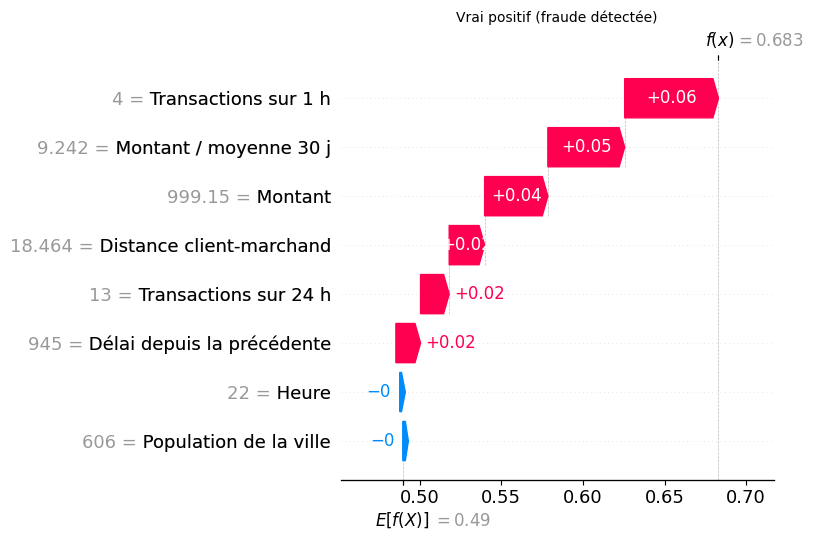

  R05_VELOCITE_1H    4 transaction(s) déjà faite(s) avec cette carte dans l'heure précédente  (+0.057)
  R07_ECART_PROFIL   Montant = 9.2 × la dépense moyenne de la carte sur 30 j  (+0.047)
  R01_MONTANT        Montant inhabituel : 999 $  (+0.039)
  R03_DISTANCE       Marchand à 18 km du domicile du client  (+0.022)
  R06_VELOCITE_24H   13 transaction(s) déjà faite(s) avec cette carte sur 24 h  (+0.018)

=== Faux positif (légitime, mais très suspecte) | score = 0.7136 (seuil 0.5556) | fraude réelle = 0 ===


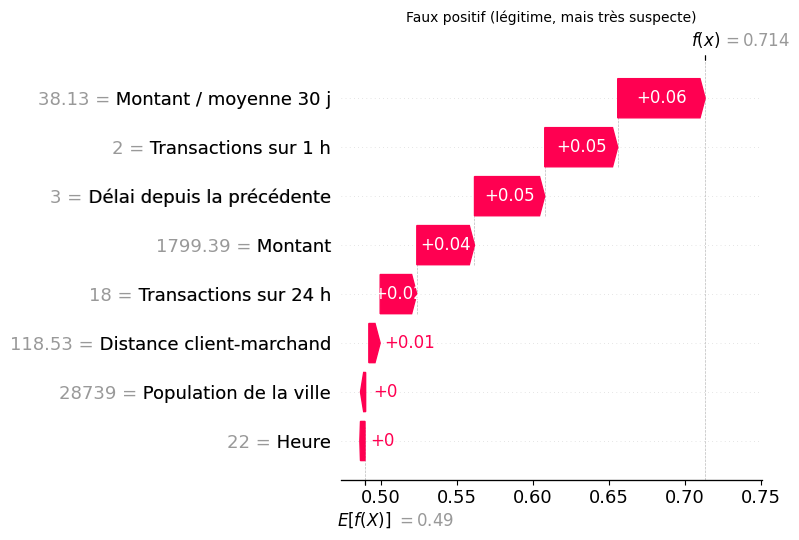

  R07_ECART_PROFIL   Montant = 38.1 × la dépense moyenne de la carte sur 30 j  (+0.058)
  R05_VELOCITE_1H    2 transaction(s) déjà faite(s) avec cette carte dans l'heure précédente  (+0.048)
  R08_DELAI          Seulement 3 s après la transaction précédente  (+0.046)
  R01_MONTANT        Montant inhabituel : 1,799 $  (+0.038)
  R06_VELOCITE_24H   18 transaction(s) déjà faite(s) avec cette carte sur 24 h  (+0.024)

=== Fraude manquée (sous le seuil) | score = 0.5555 (seuil 0.5556) | fraude réelle = 1 ===


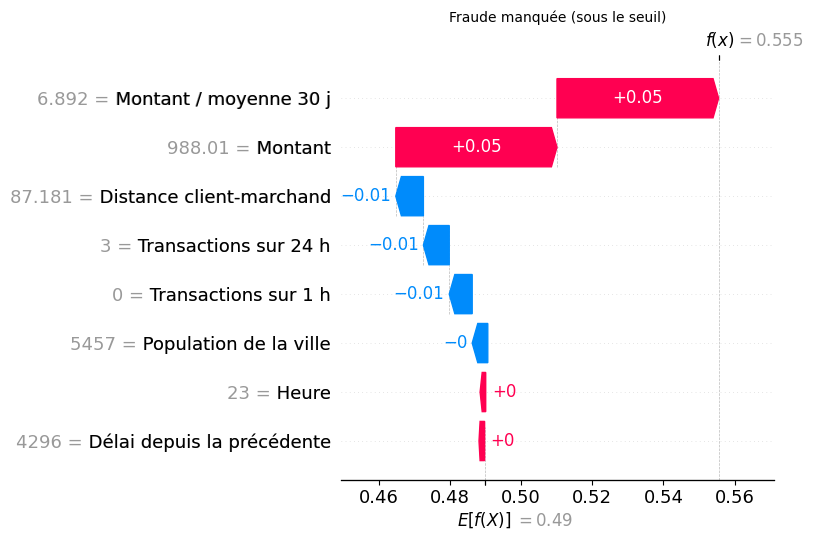

  R07_ECART_PROFIL   Montant = 6.9 × la dépense moyenne de la carte sur 30 j  (+0.045)
  R01_MONTANT        Montant inhabituel : 988 $  (+0.045)
  R04_HEURE          Transaction à 23 h, heure peu habituelle  (+0.001)
  R08_DELAI          1.2 h après la transaction précédente  (+0.000)


In [43]:
s_te, y_t = scores_te[n_if], y_te.values
top = np.argsort(-s_te)[:500]
i_tp = next(i for i in top if y_t[i] == 1)
i_fp = next(i for i in top if y_t[i] == 0)
manquees = np.where((y_t == 1) & (s_te < thr_cout))[0]
i_fn = manquees[np.argmax(s_te[manquees])]

cas = {"Vrai positif (fraude détectée)": i_tp,
       "Faux positif (légitime, mais très suspecte)": i_fp,
       "Fraude manquée (sous le seuil)": i_fn}

for titre, i in cas.items():
    expl, V, D, noms = expliquer(X_te[num].iloc[[i]], max_evals=20 * len(num) + 1)
    print(f"\n=== {titre} | score = {s_te[i]:.4f} (seuil {thr_cout:.4f}) | fraude réelle = {y_t[i]} ===")
    plt.figure()
    shap.plots.waterfall(expl[0], max_display=9, show=False)
    plt.title(titre, fontsize=10); plt.tight_layout(); plt.show()
    for m in motifs(V[0], D.iloc[0].values, noms):
        print(f"  {m['code']:<18} {m['libelle']}  (+{m['contribution']:.3f})")

### Cellule 5 : file d'alertes pour l'analyste (top 20 du test, avec codes motifs)

C'est la sortie que l'application web affichera : un rang, un score, les codes motifs.

In [44]:
top20 = np.argsort(-s_te)[:20]
expl20, V20, D20, noms = expliquer(X_te[num].iloc[top20], max_evals=10 * len(num) + 1)

file_alertes = pd.DataFrame({
    "Rang": range(1, 21),
    "Score": s_te[top20].round(3),
    "Montant ($)": D20["Montant"].round(0).values,
    "Fraude réelle": y_t[top20],
    "Codes motifs": [" | ".join(m["code"] for m in motifs(V20[j], D20.iloc[j].values, noms))
                     for j in range(20)],
})
print(f"Précision sur ces 20 alertes : {y_t[top20].mean():.0%}")
file_alertes

Précision sur ces 20 alertes : 20%


,Rang,Score,Montant ($),Fraude réelle,Codes motifs
0,1,0.714,1799.0,0,R07_ECART_PROFIL | R05_VELOCITE_1H | R08_DELAI...
1,2,0.708,2900.0,0,R07_ECART_PROFIL | R05_VELOCITE_1H | R08_DELAI...
2,3,0.694,1820.0,0,R07_ECART_PROFIL | R08_DELAI | R01_MONTANT | R...
3,4,0.692,1567.0,0,R07_ECART_PROFIL | R08_DELAI | R01_MONTANT | R...
4,5,0.691,711.0,0,R07_ECART_PROFIL | R05_VELOCITE_1H | R08_DELAI...
5,6,0.689,1410.0,0,R07_ECART_PROFIL | R05_VELOCITE_1H | R01_MONTA...
6,7,0.686,718.0,0,R05_VELOCITE_1H | R07_ECART_PROFIL | R03_DISTA...
7,8,0.686,732.0,0,R05_VELOCITE_1H | R07_ECART_PROFIL | R02_VILLE...
8,9,0.683,999.0,1,R05_VELOCITE_1H | R07_ECART_PROFIL | R01_MONTA...
9,10,0.683,1129.0,0,R07_ECART_PROFIL | R05_VELOCITE_1H | R01_MONTA...


### À commenter dans le rapport (à compléter avec tes résultats)

- **Explication globale** : quelles notions dominent le beeswarm ? Les trouves-tu dans l'exploration du Module 1 (montant, heure nocturne) et dans les repères simples du Module 3 ? Les valeurs élevées d'une variable poussent-elles toujours à droite ?
- **SHAP vs permutation** : les deux classements sont-ils cohérents ? Un écart signifie qu'une variable fait bouger le score sans aider à trouver les fraudes (bruit pour la détection).
- **Faux positif** : quels motifs ont trompé le détecteur ? Une transaction légitime mais atypique (gros montant, voyage) est le cas typique d'un détecteur non supervisé.
- **Fraude manquée** : pourquoi ressemble-t-elle à une transaction normale ? Quelles variables auraient manqué pour la repérer ?
- **Limite à écrire** : SHAP explique le score d'anomalie, pas la probabilité de fraude. Une explication dit « atypique parce que... », pas « frauduleuse parce que... ».

### Cellule 6 : sauvegarde des artefacts pour l'API

In [45]:
import joblib
joblib.dump({
    "iso": iso_b, "imputer": imp2, "scaler": sc2,
    "num": num, "skew": skew,
    "seuil_cout": float(thr_cout),          # seuil optimal en coût (Module 4)
    "seuil_budget": float(thr_budget),      # score du k-ième plus suspect (budget 1 %)
    "background": bg,                       # fond de référence SHAP
    "modele": n_if,
}, "api/artefacts.joblib")
print("Sauvegardé :", os.listdir("api"))

Sauvegardé : ['__pycache__', 'explication.py', 'artefacts.joblib']


# Module 6 : API (FastAPI)

L'API expose le détecteur et ses explications. Elle charge `artefacts.joblib` au démarrage et réutilise `explication.py`.

| Route | Rôle |
|---|---|
| `GET /health` | vérifie que le service répond |
| `GET /model-info` | modèle, variables, seuils |
| `POST /predict` | score, niveau (`normal` / `alerte` / `critique`), alerte oui/non |
| `POST /predict/batch` | idem pour une liste de transactions (jusqu'à 5 000) |
| `POST /explain` | score + contributions SHAP + **codes motifs** |

**Niveaux** : `critique` = dans le budget d'alertes de l'analyste (1 %) ; `alerte` = au-dessus du seuil optimal en coût ; `normal` sinon. La validation des entrées est faite par Pydantic (heure entre 0 et 23, montant ≥ 0, etc.).

**Entrées.** L'API reçoit les variables comportementales déjà calculées (`tx_1h`, `tx_24h`, `amt_ratio_30d`, `secs_since_prev`) : elles dépendent de l'historique de la carte, qui vit côté système appelant. `null` signifie « pas d'historique ».

In [46]:
%%writefile api/main.py
"""API FastAPI : détection de fraude explicable (Isolation Forest, non supervisé).

Lancement (depuis le dossier api/) :
    uvicorn main:app --reload
Documentation interactive : http://127.0.0.1:8000/docs
"""
import sys
from pathlib import Path
from typing import List, Optional

import joblib
import numpy as np
import pandas as pd
import shap
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

sys.path.insert(0, str(Path(__file__).parent))
from explication import regrouper, motifs  # noqa: E402

# --------------------------------------------------------------------------
# Chargement des artefacts sauvegardés par le notebook (une seule fois)
# --------------------------------------------------------------------------
ART = joblib.load(Path(__file__).parent / "artefacts.joblib")
ISO, IMP, SC = ART["iso"], ART["imputer"], ART["scaler"]
NUM, SKEW = ART["num"], ART["skew"]
SEUIL_COUT, SEUIL_BUDGET = ART["seuil_cout"], ART["seuil_budget"]
BG = ART["background"]


def _prep(D: pd.DataFrame) -> pd.DataFrame:
    """Même transformation que le notebook : log des variables asymétriques."""
    Z = D[NUM].astype("float32").copy()
    Z[SKEW] = np.log1p(Z[SKEW])
    return Z


def _score(A: np.ndarray) -> np.ndarray:
    """Score d'anomalie (élevé = suspect) à partir des 9 variables brutes."""
    D = pd.DataFrame(A, columns=NUM)
    return -ISO.score_samples(SC.transform(IMP.transform(_prep(D))))


# Explicateur SHAP indépendant du modèle : il explique directement le score
# d'anomalie, donc contribution positive = plus suspect.
EXPLAINER = shap.Explainer(_score, shap.maskers.Independent(BG, max_samples=50),
                           algorithm="permutation", feature_names=NUM)

# --------------------------------------------------------------------------
# Schémas d'entrée / sortie
# --------------------------------------------------------------------------


class Transaction(BaseModel):
    amt: float = Field(..., ge=0, description="Montant de la transaction ($)")
    city_pop: int = Field(..., ge=0, description="Population de la ville du client")
    distance_km: float = Field(..., ge=0, description="Distance client-marchand (km)")
    heure: int = Field(..., ge=0, le=23, description="Heure de la transaction (0-23)")
    tx_1h: int = Field(0, ge=0, description="Transactions de la carte dans l'heure précédente")
    tx_24h: int = Field(0, ge=0, description="Transactions de la carte sur les 24 h précédentes")
    amt_ratio_30d: Optional[float] = Field(
        None, ge=0, description="Montant / dépense moyenne 30 j (null si pas d'historique)")
    secs_since_prev: Optional[float] = Field(
        None, ge=0, description="Secondes depuis la transaction précédente (null si première)")

    model_config = {"json_schema_extra": {"example": {
        "amt": 842.5, "city_pop": 1200, "distance_km": 74.2, "heure": 2,
        "tx_1h": 2, "tx_24h": 4, "amt_ratio_30d": 9.8, "secs_since_prev": 95}}}


class Prediction(BaseModel):
    score: float
    niveau: str            # "normal" | "alerte" | "critique"
    alerte: bool
    seuil_cout: float
    seuil_budget: float


class Explication(Prediction):
    valeur_de_base: float
    contributions: List[dict]
    codes_motifs: List[dict]


def _vers_matrice(transactions: List[Transaction]) -> np.ndarray:
    lignes = []
    for t in transactions:
        angle = 2 * np.pi * t.heure / 24
        lignes.append([
            np.log1p(t.amt), t.city_pop, t.distance_km, np.sin(angle), np.cos(angle),
            t.tx_1h, t.tx_24h,
            np.nan if t.amt_ratio_30d is None else t.amt_ratio_30d,
            np.nan if t.secs_since_prev is None else t.secs_since_prev])
    return np.array(lignes, dtype=float)   # ordre = NUM


def _niveau(s: float) -> str:
    if s >= SEUIL_BUDGET:
        return "critique"      # dans le budget d'alertes de l'analyste
    if s >= SEUIL_COUT:
        return "alerte"        # au-dessus du seuil optimal en coût
    return "normal"


def _prediction(s: float) -> Prediction:
    return Prediction(score=round(float(s), 6), niveau=_niveau(s),
                      alerte=bool(s >= SEUIL_COUT),
                      seuil_cout=SEUIL_COUT, seuil_budget=SEUIL_BUDGET)


# --------------------------------------------------------------------------
# Routes
# --------------------------------------------------------------------------
app = FastAPI(title="API de détection de fraude explicable",
              description="Isolation Forest (non supervisé) + explications SHAP.",
              version="1.0")


@app.get("/health")
def health():
    return {"status": "ok"}


@app.get("/model-info")
def model_info():
    return {"modele": ART["modele"], "type": "Isolation Forest (non supervisé)",
            "variables": NUM, "seuil_cout": SEUIL_COUT, "seuil_budget": SEUIL_BUDGET,
            "convention": "score élevé = transaction plus suspecte"}


@app.post("/predict", response_model=Prediction)
def predict(t: Transaction):
    return _prediction(_score(_vers_matrice([t]))[0])


@app.post("/predict/batch", response_model=List[Prediction])
def predict_batch(transactions: List[Transaction]):
    if not 0 < len(transactions) <= 5000:
        raise HTTPException(status_code=422, detail="Fournir entre 1 et 5000 transactions.")
    return [_prediction(s) for s in _score(_vers_matrice(transactions))]


@app.post("/explain", response_model=Explication)
def explain(t: Transaction):
    X = _vers_matrice([t])
    sv = EXPLAINER(X, max_evals=10 * len(NUM) + 1)
    X_df = pd.DataFrame(X, columns=NUM)
    V, D, noms = regrouper(sv.values, X_df, NUM)
    valeurs = D.iloc[0].values
    contrib = [{"variable": n, "valeur": None if pd.isna(v) else float(v), "contribution": round(float(c), 4)}
               for n, v, c in zip(noms, valeurs, V[0])]
    contrib.sort(key=lambda d: -d["contribution"])
    pred = _prediction(_score(X)[0])
    return Explication(**pred.model_dump(), valeur_de_base=float(sv.base_values[0]),
                       contributions=contrib, codes_motifs=motifs(V[0], valeurs, noms))

Writing api/main.py


### Test de l'API depuis le notebook

On rejoue des transactions **réelles du test** et on vérifie que l'API redonne les scores du notebook.

In [47]:
sys.path.insert(0, "api")
from fastapi.testclient import TestClient
import main
client = TestClient(main.app)

def vers_payload(r):
    f = lambda v: None if pd.isna(v) else float(v)
    return {"amt": float(r["amt"]), "city_pop": int(r["city_pop"]),
            "distance_km": float(r["distance_km"]),
            "heure": int(round(np.degrees(np.arctan2(r["hour_sin"], r["hour_cos"])) / 15)) % 24,
            "tx_1h": int(r["tx_1h"]), "tx_24h": int(r["tx_24h"]),
            "amt_ratio_30d": f(r["amt_ratio_30d"]), "secs_since_prev": f(r["secs_since_prev"])}

print(client.get("/health").json())
print(client.get("/model-info").json()["seuil_cout"])

for titre, i in cas.items():
    p = vers_payload(X_te.iloc[i])
    r = client.post("/explain", json=p).json()
    print(f"\n{titre}: score API = {r['score']:.4f} | score notebook = {s_te[i]:.4f} | niveau = {r['niveau']}")
    assert abs(r["score"] - s_te[i]) < 1e-3, "l'API ne reproduit pas le score du notebook"
    for m in r["codes_motifs"]:
        print("   ", m["code"], "-", m["libelle"])

# Validation des entrées : une heure impossible doit être refusée (code 422)
mauvais = vers_payload(X_te.iloc[i_tp]); mauvais["heure"] = 27
print("\nHeure = 27 ->", client.post("/predict", json=mauvais).status_code)

# Lot
lot = [vers_payload(X_te.iloc[i]) for i in top20]
niveaux = [x["niveau"] for x in client.post("/predict/batch", json=lot).json()]
print({n: niveaux.count(n) for n in set(niveaux)})

{'status': 'ok'}
0.5555978654178164

Vrai positif (fraude détectée): score API = 0.6830 | score notebook = 0.6830 | niveau = critique
    R05_VELOCITE_1H - 4 transaction(s) déjà faite(s) avec cette carte dans l'heure précédente
    R07_ECART_PROFIL - Montant = 9.2 × la dépense moyenne de la carte sur 30 j
    R01_MONTANT - Montant inhabituel : 999 $
    R03_DISTANCE - Marchand à 18 km du domicile du client
    R06_VELOCITE_24H - 13 transaction(s) déjà faite(s) avec cette carte sur 24 h

Faux positif (légitime, mais très suspecte): score API = 0.7136 | score notebook = 0.7136 | niveau = critique
    R07_ECART_PROFIL - Montant = 38.1 × la dépense moyenne de la carte sur 30 j
    R05_VELOCITE_1H - 2 transaction(s) déjà faite(s) avec cette carte dans l'heure précédente
    R08_DELAI - Seulement 3 s après la transaction précédente
    R01_MONTANT - Montant inhabituel : 1,799 $
    R06_VELOCITE_24H - 18 transaction(s) déjà faite(s) avec cette carte sur 24 h

Fraude manquée (sous le seuil): s

### (Optionnel) Lancer un vrai serveur

En local, depuis le dossier `api/` : `uvicorn main:app --reload`, puis ouvre `http://127.0.0.1:8000/docs` (documentation Swagger interactive, utile pour la démonstration). Dans Colab, tu peux le tester ainsi :

In [48]:
import subprocess, requests
proc = subprocess.Popen(["uvicorn", "main:app", "--port", "8000"], cwd="api")
time.sleep(15)
r = requests.post("http://127.0.0.1:8000/explain", json=vers_payload(X_te.iloc[i_tp]))
print(r.status_code); print(r.json()["codes_motifs"])
proc.terminate()

200
[{'code': 'R05_VELOCITE_1H', 'variable': 'Transactions sur 1 h', 'libelle': "4 transaction(s) déjà faite(s) avec cette carte dans l'heure précédente", 'contribution': 0.0578}, {'code': 'R07_ECART_PROFIL', 'variable': 'Montant / moyenne 30 j', 'libelle': 'Montant = 9.2 × la dépense moyenne de la carte sur 30 j', 'contribution': 0.0468}, {'code': 'R01_MONTANT', 'variable': 'Montant', 'libelle': 'Montant inhabituel : 999 $', 'contribution': 0.0383}, {'code': 'R03_DISTANCE', 'variable': 'Distance client-marchand', 'libelle': 'Marchand à 18 km du domicile du client', 'contribution': 0.0217}, {'code': 'R06_VELOCITE_24H', 'variable': 'Transactions sur 24 h', 'libelle': '13 transaction(s) déjà faite(s) avec cette carte sur 24 h', 'contribution': 0.018}]


In [53]:
import sklearn; print(sklearn.__version__)
!zip -r api.zip api

1.6.1
  adding: api/ (stored 0%)
  adding: api/main.py (deflated 61%)
  adding: api/__pycache__/ (stored 0%)
  adding: api/__pycache__/main.cpython-313.pyc (deflated 45%)
  adding: api/__pycache__/explication.cpython-313.pyc (deflated 41%)
  adding: api/explication.py (deflated 61%)
  adding: api/artefacts.joblib (deflated 73%)


In [55]:
def table(Xd, yy, s, jeu):
    h = (np.round(np.degrees(np.arctan2(Xd["hour_sin"], Xd["hour_cos"])) / 15) % 24).astype(int)
    return pd.DataFrame({"jeu": jeu, "score": s, "fraude": yy.values, "amt": Xd["amt"].values,
        "city_pop": Xd["city_pop"].values, "distance_km": Xd["distance_km"].values, "heure": h.values,
        "tx_1h": Xd["tx_1h"].values, "tx_24h": Xd["tx_24h"].values,
        "amt_ratio_30d": Xd["amt_ratio_30d"].values, "secs_since_prev": Xd["secs_since_prev"].values})

donnees = pd.concat([table(X_va, y_va, scores_va[n_if], "validation"),
                     table(X_te, y_te, scores_te[n_if], "test")])
donnees.to_csv("api/donnees_app.csv.gz", index=False)
print(donnees.shape)

(740958, 11)


In [56]:
!zip -r api.zip api

updating: api/ (stored 0%)
updating: api/main.py (deflated 61%)
updating: api/__pycache__/ (stored 0%)
updating: api/__pycache__/main.cpython-313.pyc (deflated 45%)
updating: api/__pycache__/explication.cpython-313.pyc (deflated 41%)
updating: api/explication.py (deflated 61%)
updating: api/artefacts.joblib (deflated 73%)
  adding: api/donnees_app.csv.gz (deflated 0%)
